# Customer Segmentation & Recommender — Walkthrough

This notebook runs the project **one step at a time** so you can see what every stage does.
The same code lives in `src/` and runs end to end with `python train.py`.

**Pipeline:** raw transactions → clean → RFM features → scale + PCA → choose k → K-Means → name segments → seasonality → recommender → evaluation

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
pd.set_option("display.width", 140)

## 1. Load and clean the data
Each raw row = one product line on one invoice. We drop rows without a `CustomerID`,
cancelled invoices (`InvoiceNo` starting with **C**), zero/negative quantities or prices,
and duplicates. Then we add `TotalPrice = Quantity × UnitPrice`.

In [2]:
from src.data_loader import load_raw, clean
raw = load_raw()
raw.head()

[load] reading Online Retail.xlsx ...
[load] 541,909 rows, 4,372 customers (before cleaning)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Missing CustomerID:", raw["CustomerID"].isna().sum())
print("Cancelled rows    :", raw["InvoiceNo"].astype(str).str.startswith("C").sum())
df = clean(raw)
df.head()

Missing CustomerID: 135080
Cancelled rows    : 9288
[clean] kept 392,692 of 541,909 rows | 4,338 customers | 3,665 products


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 2. RFM feature engineering
One row per customer:

| Feature | Meaning |
|---|---|
| **Recency** | days since last purchase (lower = better) |
| **Frequency** | number of distinct invoices |
| **Monetary** | total spend |
| AvgOrderValue | Monetary ÷ Frequency |
| UniqueProducts | variety of products bought |
| Tenure | days between first and last purchase |

In [4]:
from src.features import build_rfm, add_rfm_scores
rfm = add_rfm_scores(build_rfm(df))
rfm.describe().round(1)

[rfm] built features for 4,338 customers (snapshot date 2011-12-10)


,Recency,Frequency,Monetary,AvgOrderValue,UniqueProducts,Tenure,R_Score,F_Score,M_Score
count,4338.0,4338.0,4338.0,4338.0,4338.0,4338.0,4338.0,4338.0,4338.0
mean,92.5,4.3,2048.7,417.6,61.5,130.4,3.0,3.0,3.0
std,100.0,7.7,8985.2,1796.5,85.4,132.0,1.4,1.4,1.4
min,1.0,1.0,3.8,3.4,1.0,0.0,1.0,1.0,1.0
25%,18.0,1.0,306.5,177.9,16.0,0.0,2.0,2.0,2.0
50%,51.0,2.0,668.6,291.9,35.0,92.5,3.0,3.0,3.0
75%,142.0,5.0,1660.6,428.3,77.0,251.8,4.0,4.0,4.0
max,374.0,209.0,280206.0,84236.2,1787.0,373.0,5.0,5.0,5.0


Notice how **Monetary** and **Frequency** have a mean far above the median (50%) — a few customers spend enormously.
That skew would dominate a distance-based algorithm, so we apply `log1p` before scaling.

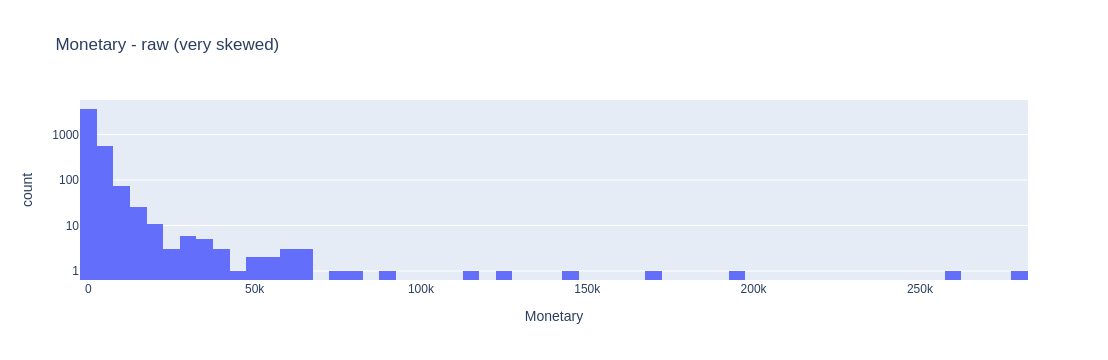

In [5]:
import plotly.express as px
px.histogram(rfm, x="Monetary", nbins=80, title="Monetary - raw (very skewed)", log_y=True).show()

## 3. Scale → PCA
* **StandardScaler** puts every feature on the same scale (mean 0, std 1).
* **PCA** turns correlated features into uncorrelated components; we keep enough to explain 90 % of the variance.

In [6]:
from src.clustering import preprocess
X, scaler, pca = preprocess(rfm)
print("Shape after PCA:", X.shape)
print("Variance explained per component:", pca.explained_variance_ratio_.round(3))

[pca] keeping 4 of 6 components -> 95.9% variance explained
Shape after PCA: (4338, 4)
Variance explained per component: [0.61  0.187 0.093 0.069]


In [7]:
# Which original features drive each component?
from src.config import CLUSTER_FEATURES
pd.DataFrame(pca.components_, columns=CLUSTER_FEATURES,
             index=[f"PC{i+1}" for i in range(pca.n_components_)]).round(2)

,Recency,Frequency,Monetary,AvgOrderValue,UniqueProducts,Tenure
PC1,-0.35,0.46,0.49,0.26,0.42,0.42
PC2,0.34,-0.27,0.27,0.80,0.09,-0.32
PC3,0.87,0.22,0.08,-0.18,0.11,0.39
PC4,0.03,-0.19,-0.26,-0.19,0.89,-0.24


## 4. How many clusters? Elbow (WCSS) + Silhouette
* **WCSS** – total squared distance of points to their cluster centre. It always falls as k grows; the *elbow* is where extra clusters stop helping much.
* **Silhouette** – how well each customer fits its own cluster vs the next-closest one (−1 to 1, higher is better).

In [ ]:
from src.clustering import evaluate_k, find_elbow
from src import visualize as viz
k_eval = evaluate_k(X)
print("Elbow suggests k =", find_elbow(k_eval))
viz.plot_k_evaluation(k_eval, 3).show()

## 5. Fit K-Means with k = 3 and name the segments
K-Means labels are just 0/1/2. We rank clusters by `Frequency + Monetary − Recency` (standardised) and name them
**A Champions**, **B Budget-Conscious**, **C At-Risk**.

In [ ]:
from src.clustering import fit_kmeans, name_clusters, segment_profile, SEGMENT_NAMES
km, sil = fit_kmeans(X, 3)
rfm["Cluster"] = km.labels_
mapping = name_clusters(rfm)
rfm["Segment"] = rfm["Cluster"].map(mapping)
rfm["SegmentName"] = rfm["Segment"].map(SEGMENT_NAMES)
for i in range(3):
    rfm[f"PC{i+1}"] = X[:, i]
profile = segment_profile(rfm)
profile

In [ ]:
viz.plot_clusters_3d(rfm).show()

## 6. Seasonality

In [ ]:
from src.seasonality import monthly_by_segment, seasonal_summary
monthly = monthly_by_segment(df, rfm)
viz.plot_monthly_revenue(monthly).show()
seasonal_summary(monthly)

## 7. Segment-based recommender
For each segment we rank products with its own strategy, then for a customer we drop items they've already bought.

In [ ]:
from src.recommender import build_segment_bestsellers, customer_history, recommend
best = build_segment_bestsellers(df, rfm)
hist = customer_history(df)
best.groupby("Segment").head(5)[["Segment", "Rank", "StockCode", "Description", "UnitPrice"]]

In [ ]:
example = rfm.index[0]
seg, recs = recommend(example, rfm, best, hist, n=10)
print(f"Customer {example} is in segment {seg} ({SEGMENT_NAMES[seg]})")
recs

## 8. Does segment targeting help? (time-based evaluation)
Train on purchases before **2011-09-01**, then check what customers actually bought afterwards.
We compare against showing everyone the same global best-seller list.

In [ ]:
from src.recommender import evaluate
summary = evaluate(df, "2011-09-01")
{k: v for k, v in summary.items() if k != "by_segment"}

## Done 🎉
Run `python train.py` to produce all artifacts and charts, then `streamlit run app.py` for the dashboard.